### Install the Dataset Download Utility

In [3]:
!pip install -q gdown

### Download the Flower Image Dataset

In [4]:
!gdown 1NkwiO41LZtZiCXD80mJJv1XzaM3tv7ud


Downloading...
From (original): https://drive.google.com/uc?id=1NkwiO41LZtZiCXD80mJJv1XzaM3tv7ud
From (redirected): https://drive.google.com/uc?id=1NkwiO41LZtZiCXD80mJJv1XzaM3tv7ud&confirm=t&uuid=cac1b0c1-51cb-41c6-a42b-218353378c6d
To: /content/flowers-20251228T193800Z-3-001.zip
100% 264M/264M [00:07<00:00, 36.6MB/s]


### Extract the Flower Dataset Archive

In [5]:
!unzip /content/flowers-20251228T193800Z-3-001.zip

Streaming output truncated to the last 5000 lines.
  inflating: flowers/val/Sunflower/a76fc2cc1e.jpg  
  inflating: flowers/val/Sunflower/ee0d3d759c.jpg  
  inflating: flowers/val/Sunflower/4f700f9339.jpg  
  inflating: flowers/val/Sunflower/6b16a59c59.jpg  
  inflating: flowers/val/Sunflower/9aa5683fa9.jpg  
  inflating: flowers/val/Sunflower/2229f2ab59.jpg  
  inflating: flowers/val/Sunflower/b0153af792.jpg  
  inflating: flowers/val/Sunflower/014cddbeef.jpg  
  inflating: flowers/val/Sunflower/78fb7e5be7.jpg  
  inflating: flowers/val/Sunflower/76504996c4.jpg  
  inflating: flowers/train/.DS_Store  
  inflating: flowers/val/Sunflower/15d956cb4a.jpg  
  inflating: flowers/val/Sunflower/7e0b30d246.jpg  
  inflating: flowers/val/Sunflower/8495f8886a.jpg  
  inflating: flowers/val/Sunflower/c81aba9f13.jpg  
  inflating: flowers/val/Sunflower/60f4d42565.jpg  
  inflating: flowers/val/Sunflower/790b766d3f.jpg  
  inflating: flowers/val/Sunflower/8ed458f9fe.jpg  
  inflating: flowers/val/S

## Question 8 - Flower Image Classification

### Imports

### Import PyTorch and Visualization Dependencies

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import os
import copy

### Configuration

### Set Training Hyperparameters and Device

In [7]:
data_dir = './flowers'
batch_size = 32
num_epochs = 50
learning_rate = 0.001
weight_decay = 1e-4
patience = 5
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### Data Preprocessing

### Prepare 128 × 128 Images and Data Loaders

In [8]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(os.path.join(data_dir, 'train'), transform=transform)
val_dataset = datasets.ImageFolder(os.path.join(data_dir, 'val'), transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

num_classes = len(train_dataset.classes)
input_size = 3 * 128 * 128

### Model Definition

### Define Linear, Hidden-Layer, and Regularized Classifiers

In [ ]:
class LinearModel(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(input_size, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc(x)
        return x

class OneHiddenLayerModel(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_size, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

class ImprovedModel(nn.Module):
    def __init__(self, input_size, num_classes, dropout_prob=0.5):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_size, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_prob)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

### Training Function

### Train Models with Validation and Early Stopping

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, patience, device):

    best_val_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': []
    }

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = correct / total

        model.eval()
        running_val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = val_correct / val_total

        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{num_epochs} - "
              f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered after {epoch+1} epochs")
                break

    model.load_state_dict(best_model_wts)
    return model, history

### Plotting Function

### Plot Training and Validation Learning Curves

In [11]:
def plot_history(history, title):
    epochs = range(1, len(history['train_loss'])+1)
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(epochs, history['train_loss'], 'b-', label='Train Loss')
    plt.plot(epochs, history['val_loss'], 'r-', label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.title(f'{title} - Loss')

    plt.subplot(1,2,2)
    plt.plot(epochs, history['train_acc'], 'b-', label='Train Acc')
    plt.plot(epochs, history['val_acc'], 'r-', label='Val Acc')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.title(f'{title} - Accuracy')
    plt.tight_layout()
    plt.show()

### Run Experiments

### Train and Compare Three Classifiers from Scratch

Training Linear Model
Epoch 1/50 - Train Loss: 11.6362, Train Acc: 0.3947 | Val Loss: 7.1509, Val Acc: 0.4471
Epoch 2/50 - Train Loss: 7.1761, Train Acc: 0.5060 | Val Loss: 8.2265, Val Acc: 0.4728
Epoch 3/50 - Train Loss: 6.0084, Train Acc: 0.5651 | Val Loss: 13.0273, Val Acc: 0.4283
Epoch 4/50 - Train Loss: 7.4141, Train Acc: 0.5694 | Val Loss: 6.1685, Val Acc: 0.5223
Epoch 5/50 - Train Loss: 6.4528, Train Acc: 0.5948 | Val Loss: 7.4756, Val Acc: 0.5045
Epoch 6/50 - Train Loss: 4.5969, Train Acc: 0.6579 | Val Loss: 18.8153, Val Acc: 0.4342
Epoch 7/50 - Train Loss: 3.5713, Train Acc: 0.7008 | Val Loss: 7.3543, Val Acc: 0.5292
Epoch 8/50 - Train Loss: 5.0811, Train Acc: 0.6664 | Val Loss: 11.9051, Val Acc: 0.5005
Epoch 9/50 - Train Loss: 4.3330, Train Acc: 0.7091 | Val Loss: 6.0761, Val Acc: 0.5767
Epoch 10/50 - Train Loss: 4.5035, Train Acc: 0.7151 | Val Loss: 9.0222, Val Acc: 0.5341
Epoch 11/50 - Train Loss: 2.6018, Train Acc: 0.7700 | Val Loss: 9.2034, Val Acc: 0.5707
Epoch 12/50 - T

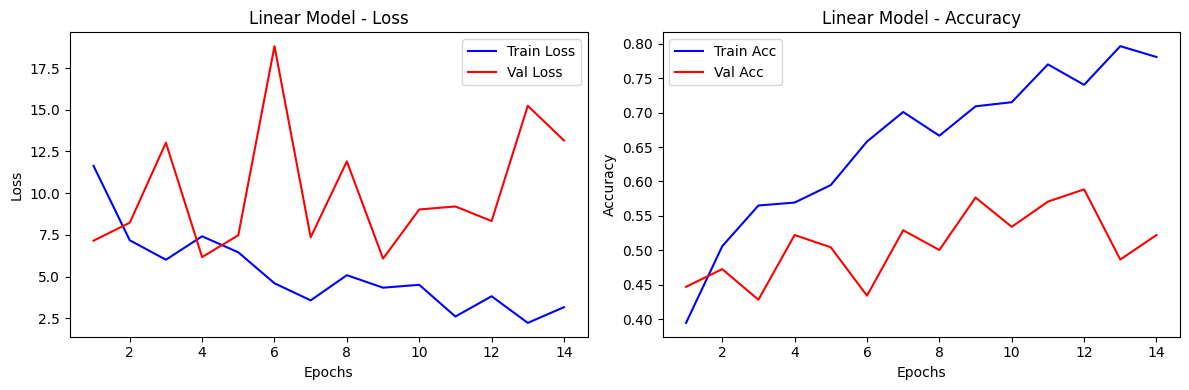

Training One Hidden Layer Model (128 neurons, ReLU)
Epoch 1/50 - Train Loss: 11.0944, Train Acc: 0.4119 | Val Loss: 8.5476, Val Acc: 0.4510
Epoch 2/50 - Train Loss: 4.5075, Train Acc: 0.5437 | Val Loss: 5.6176, Val Acc: 0.4777
Epoch 3/50 - Train Loss: 3.0142, Train Acc: 0.5689 | Val Loss: 3.3821, Val Acc: 0.4985
Epoch 4/50 - Train Loss: 1.5857, Train Acc: 0.6524 | Val Loss: 2.7582, Val Acc: 0.5648
Epoch 5/50 - Train Loss: 1.5468, Train Acc: 0.6694 | Val Loss: 2.1331, Val Acc: 0.6152
Epoch 6/50 - Train Loss: 1.1979, Train Acc: 0.7093 | Val Loss: 3.2430, Val Acc: 0.5628
Epoch 7/50 - Train Loss: 1.1198, Train Acc: 0.7163 | Val Loss: 2.9962, Val Acc: 0.5856
Epoch 8/50 - Train Loss: 1.1841, Train Acc: 0.7273 | Val Loss: 3.3295, Val Acc: 0.5707
Epoch 9/50 - Train Loss: 1.0699, Train Acc: 0.7500 | Val Loss: 2.0359, Val Acc: 0.6291
Epoch 10/50 - Train Loss: 0.7688, Train Acc: 0.7877 | Val Loss: 2.0478, Val Acc: 0.6597
Epoch 11/50 - Train Loss: 0.8630, Train Acc: 0.7764 | Val Loss: 2.3139, Val 

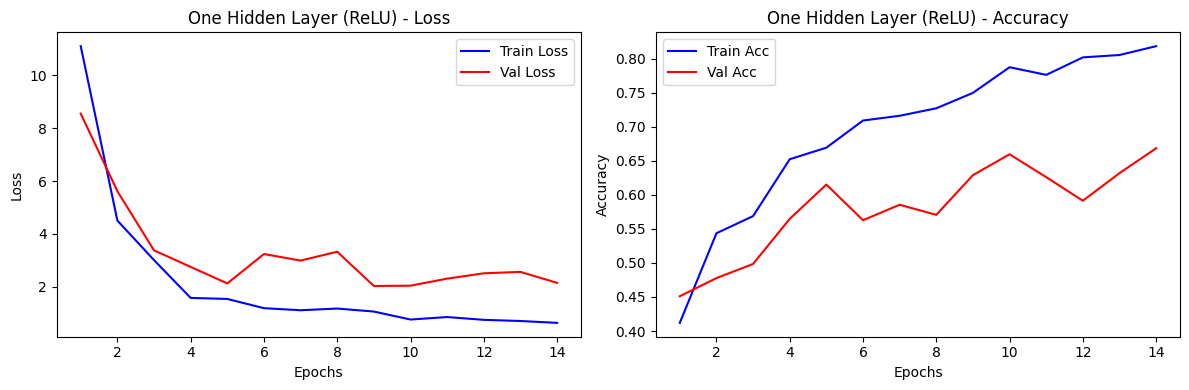

Training Improved Model (BatchNorm, Dropout, L2 reg)
Epoch 1/50 - Train Loss: 1.4427, Train Acc: 0.3750 | Val Loss: 1.3098, Val Acc: 0.4688
Epoch 2/50 - Train Loss: 1.2918, Train Acc: 0.4666 | Val Loss: 1.2108, Val Acc: 0.4946
Epoch 3/50 - Train Loss: 1.2130, Train Acc: 0.5020 | Val Loss: 1.1862, Val Acc: 0.4985
Epoch 4/50 - Train Loss: 1.1578, Train Acc: 0.5274 | Val Loss: 1.1494, Val Acc: 0.5351
Epoch 5/50 - Train Loss: 1.1286, Train Acc: 0.5427 | Val Loss: 1.1381, Val Acc: 0.5381
Epoch 6/50 - Train Loss: 1.1084, Train Acc: 0.5546 | Val Loss: 1.1231, Val Acc: 0.5371
Epoch 7/50 - Train Loss: 1.0890, Train Acc: 0.5758 | Val Loss: 1.0954, Val Acc: 0.5589
Epoch 8/50 - Train Loss: 1.0823, Train Acc: 0.5758 | Val Loss: 1.1365, Val Acc: 0.5430
Epoch 9/50 - Train Loss: 1.0183, Train Acc: 0.6078 | Val Loss: 1.0698, Val Acc: 0.5945
Epoch 10/50 - Train Loss: 1.0134, Train Acc: 0.6023 | Val Loss: 1.0559, Val Acc: 0.5895
Epoch 11/50 - Train Loss: 0.9959, Train Acc: 0.6123 | Val Loss: 1.0262, Val 

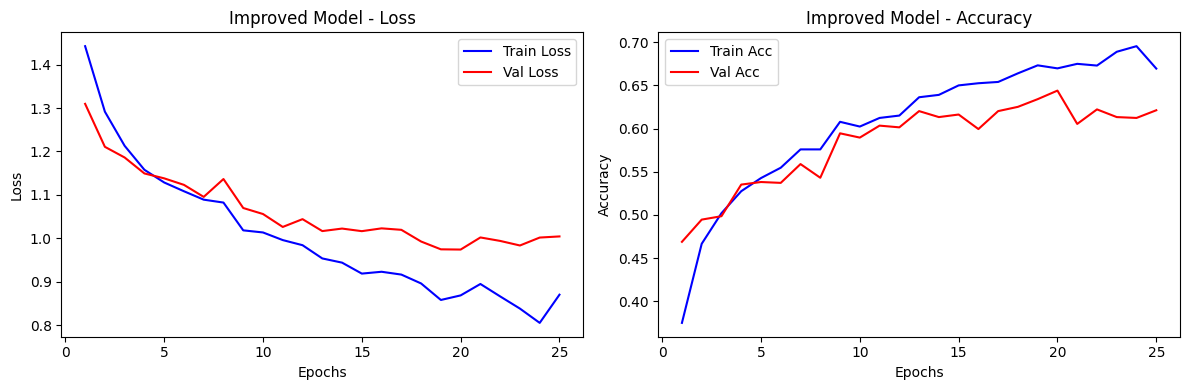

Final Validation Accuracies:
Linear Model      : 0.5223
One Hidden Layer  : 0.6686
Improved Model    : 0.6212


In [ ]:
criterion = nn.CrossEntropyLoss()

print("="*50)
print("Training Linear Model")
model_linear = LinearModel(input_size, num_classes).to(device)
optimizer_linear = optim.Adam(model_linear.parameters(), lr=learning_rate)
best_linear, history_linear = train_model(
    model_linear, train_loader, val_loader, criterion, optimizer_linear,
    num_epochs, patience, device
)
plot_history(history_linear, "Linear Model")

print("="*50)
print("Training One Hidden Layer Model (128 neurons, ReLU)")
model_hidden = OneHiddenLayerModel(input_size, num_classes).to(device)
optimizer_hidden = optim.Adam(model_hidden.parameters(), lr=learning_rate)
best_hidden, history_hidden = train_model(
    model_hidden, train_loader, val_loader, criterion, optimizer_hidden,
    num_epochs, patience, device
)
plot_history(history_hidden, "One Hidden Layer (ReLU)")

print("="*50)
print("Training Improved Model (BatchNorm, Dropout, L2 reg)")
model_improved = ImprovedModel(input_size, num_classes, dropout_prob=0.5).to(device)
optimizer_improved = optim.Adam(model_improved.parameters(), lr=learning_rate, weight_decay=weight_decay)
best_improved, history_improved = train_model(
    model_improved, train_loader, val_loader, criterion, optimizer_improved,
    num_epochs, patience, device
)
plot_history(history_improved, "Improved Model")

print("="*50)
print("Final Validation Accuracies:")
print(f"Linear Model      : {history_linear['val_acc'][-1]:.4f}")
print(f"One Hidden Layer  : {history_hidden['val_acc'][-1]:.4f}")
print(f"Improved Model    : {history_improved['val_acc'][-1]:.4f}")

## Part II: Transfer Learning (Frozen Backbones)

### Configure 224 × 224 Image Preprocessing for Transfer Learning

In [17]:
criterion = nn.CrossEntropyLoss()
transform_224 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

### Create Transfer-Learning Data Loaders

In [19]:
train_dataset_224 = datasets.ImageFolder(os.path.join(data_dir, 'train'), transform=transform_224)
val_dataset_224 = datasets.ImageFolder(os.path.join(data_dir, 'val'), transform=transform_224)

train_loader_224 = DataLoader(train_dataset_224, batch_size=batch_size, shuffle=True)
val_loader_224 = DataLoader(val_dataset_224, batch_size=batch_size, shuffle=False)

num_classes = len(train_dataset_224.classes)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### AlexNet

### Train a Frozen AlexNet with a New Classification Head

Training Transfer Learning: AlexNet (frozen backbone)


Using cache found in /root/.cache/torch/hub/pytorch_vision_main


Epoch 1/50 - Train Loss: 0.5975, Train Acc: 0.7812 | Val Loss: 0.4153, Val Acc: 0.8605
Epoch 2/50 - Train Loss: 0.3304, Train Acc: 0.8802 | Val Loss: 0.3216, Val Acc: 0.8902
Epoch 3/50 - Train Loss: 0.2697, Train Acc: 0.9049 | Val Loss: 0.2932, Val Acc: 0.8942
Epoch 4/50 - Train Loss: 0.2337, Train Acc: 0.9139 | Val Loss: 0.3062, Val Acc: 0.8981
Epoch 5/50 - Train Loss: 0.2000, Train Acc: 0.9266 | Val Loss: 0.2452, Val Acc: 0.9139
Epoch 6/50 - Train Loss: 0.1942, Train Acc: 0.9249 | Val Loss: 0.2369, Val Acc: 0.9219
Epoch 7/50 - Train Loss: 0.1643, Train Acc: 0.9426 | Val Loss: 0.2695, Val Acc: 0.9100
Epoch 8/50 - Train Loss: 0.1503, Train Acc: 0.9429 | Val Loss: 0.2399, Val Acc: 0.9238
Epoch 9/50 - Train Loss: 0.1596, Train Acc: 0.9396 | Val Loss: 0.2286, Val Acc: 0.9238
Epoch 10/50 - Train Loss: 0.1554, Train Acc: 0.9424 | Val Loss: 0.2536, Val Acc: 0.9169
Epoch 11/50 - Train Loss: 0.1422, Train Acc: 0.9461 | Val Loss: 0.2431, Val Acc: 0.9179
Epoch 12/50 - Train Loss: 0.1434, Train A

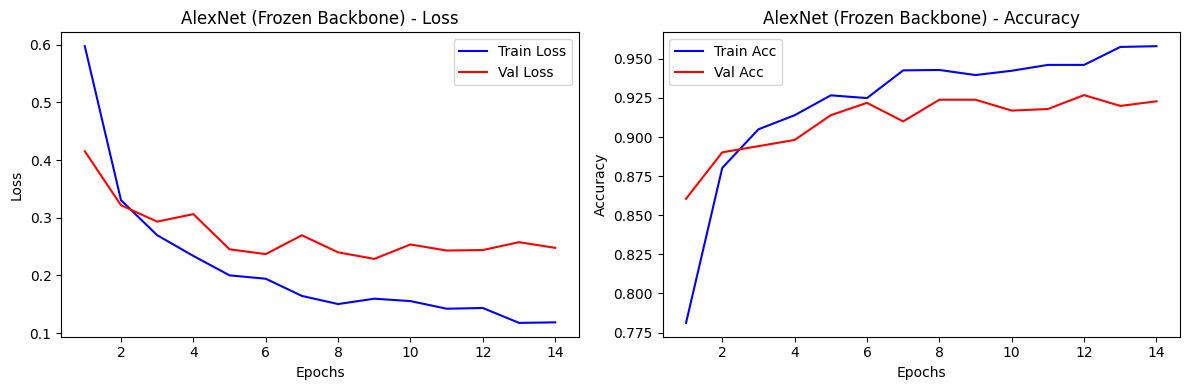

In [36]:
print("="*50)
print("Training Transfer Learning: AlexNet (frozen backbone)")

alexnet = torch.hub.load('pytorch/vision', 'alexnet', pretrained=True)

for param in alexnet.parameters():
    param.requires_grad = False

num_features = alexnet.classifier[6].in_features
alexnet.classifier[6] = nn.Linear(num_features, num_classes)

for param in alexnet.classifier[6].parameters():
    param.requires_grad = True

alexnet = alexnet.to(device)

optimizer_alex = optim.Adam(filter(lambda p: p.requires_grad, alexnet.parameters()), lr=learning_rate)

best_alex, history_alex = train_model(
    alexnet, train_loader_224, val_loader_224, criterion, optimizer_alex,
    num_epochs, patience, device
)
plot_history(history_alex, "AlexNet (Frozen Backbone)")

### VGG16

### Train a Frozen VGG16 with a New Classification Head

Training Transfer Learning: VGG16 (frozen backbone)


Using cache found in /root/.cache/torch/hub/pytorch_vision_main


Epoch 1/50 - Train Loss: 0.7513, Train Acc: 0.7183 | Val Loss: 0.5387, Val Acc: 0.8150
Epoch 2/50 - Train Loss: 0.5215, Train Acc: 0.8104 | Val Loss: 0.4775, Val Acc: 0.8388
Epoch 3/50 - Train Loss: 0.4728, Train Acc: 0.8268 | Val Loss: 0.4371, Val Acc: 0.8566
Epoch 4/50 - Train Loss: 0.4333, Train Acc: 0.8393 | Val Loss: 0.4299, Val Acc: 0.8516
Epoch 5/50 - Train Loss: 0.4265, Train Acc: 0.8428 | Val Loss: 0.4377, Val Acc: 0.8487
Epoch 6/50 - Train Loss: 0.3930, Train Acc: 0.8558 | Val Loss: 0.4063, Val Acc: 0.8684
Epoch 7/50 - Train Loss: 0.3970, Train Acc: 0.8498 | Val Loss: 0.3874, Val Acc: 0.8764
Epoch 8/50 - Train Loss: 0.3755, Train Acc: 0.8520 | Val Loss: 0.3913, Val Acc: 0.8645
Epoch 9/50 - Train Loss: 0.3784, Train Acc: 0.8578 | Val Loss: 0.3937, Val Acc: 0.8714
Epoch 10/50 - Train Loss: 0.3682, Train Acc: 0.8630 | Val Loss: 0.3743, Val Acc: 0.8704
Epoch 11/50 - Train Loss: 0.3613, Train Acc: 0.8605 | Val Loss: 0.3667, Val Acc: 0.8783
Epoch 12/50 - Train Loss: 0.3852, Train A

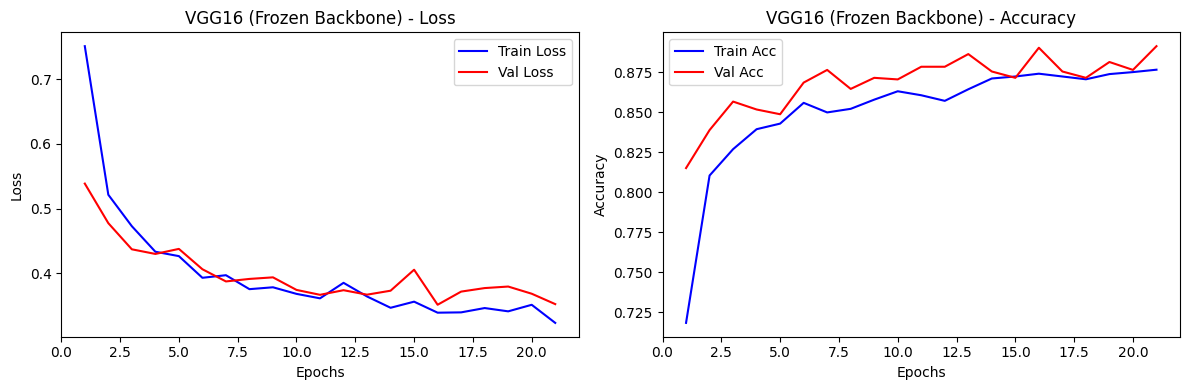

In [20]:
print("="*50)
print("Training Transfer Learning: VGG16 (frozen backbone)")

vgg16 = torch.hub.load('pytorch/vision', 'vgg16', pretrained=True)

for param in vgg16.parameters():
    param.requires_grad = False

num_features = vgg16.classifier[6].in_features
vgg16.classifier[6] = nn.Linear(num_features, num_classes)

for param in vgg16.classifier[6].parameters():
    param.requires_grad = True

vgg16 = vgg16.to(device)

optimizer_vgg = optim.Adam(filter(lambda p: p.requires_grad, vgg16.parameters()), lr=learning_rate)

best_vgg, history_vgg = train_model(
    vgg16, train_loader_224, val_loader_224, criterion, optimizer_vgg,
    num_epochs, patience, device
)
plot_history(history_vgg, "VGG16 (Frozen Backbone)")